In [ ]:

from google.colab import drive
from pathlib import Path

# Connect Google Drive
drive.mount("/content/drive")

# Define the main project directory
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis"
)

# Create project folders
folders = [
    "data/raw",
    "data/interim",
    "data/processed",
    "notebooks",
    "src",
    "reports/figures",
    "reports/tables",
    "power_bi",
    "streamlit_app",
    "models",
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True, exist_ok=True
    )

print("Project folders created successfully!")
print("Project location:", PROJECT_DIR)


Mounted at /content/drive
Project folders created successfully!
Project location: /content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis


## **LOAD THE DATASET**

In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis/data/raw/Atlantic_Spain.csv"

df = pd.read_csv(file_path)
df.head()

,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
0,18-05-2024,1,Supernova,Saiko,84,190909,single,1,False,https://i.scdn.co/image/ab67616d0000b273c3f5b9...
1,18-05-2024,2,EL TONTO,Lola Indigo,83,187986,album,11,False,https://i.scdn.co/image/ab67616d0000b273daab36...
2,18-05-2024,3,Acróstico,Shakira,81,170785,single,1,False,https://i.scdn.co/image/ab67616d0000b273bd6bbd...
3,18-05-2024,4,BESO,ROSALÍA & Rauw Alejandro,96,194543,single,3,False,https://i.scdn.co/image/ab67616d0000b2734d6cf0...
4,18-05-2024,5,El Merengue,Marshmello & Manuel Turizo,91,189668,single,1,False,https://i.scdn.co/image/ab67616d0000b273f40467...


# **Inspect the dataset**

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Column names:
['date', 'position', 'song', 'artist', 'popularity', 'duration_ms', 'album_type', 'total_tracks', 'is_explicit', 'album_cover_url']

Data types:
date               object
position            int64
song               object
artist             object
popularity          int64
duration_ms         int64
album_type         object
total_tracks        int64
is_explicit          bool
album_cover_url    object
dtype: object

Missing values:
date               0
position           0
song               0
artist             0
popularity         0
duration_ms        0
album_type         0
total_tracks       0
is_explicit        0
album_cover_url    0
dtype: int64


# **Check data quality**

In [ ]:
# 1. Check the number of rows and columns
print("Dataset shape:", df.shape)

# 2. Check exact duplicate rows
print("\nExact duplicate rows:", df.duplicated().sum())

# 3. Check the date range and unique dates
print("\nFirst date values:")
print(df["date"].head())

print("\nNumber of unique date values:", df["date"].nunique())

# 4. Check album types
print("\nAlbum type counts:")
print(df["album_type"].value_counts())

# 5. Check position values
print("\nPosition range:")
print("Minimum:", df["position"].min())
print("Maximum:", df["position"].max())

# 6. Check numerical statistics
print("\nNumerical summary:")
display(df[["position", "popularity", "duration_ms", "total_tracks"]].describe())

Dataset shape: (27800, 10)

Exact duplicate rows: 15

First date values:
0    18-05-2024
1    18-05-2024
2    18-05-2024
3    18-05-2024
4    18-05-2024
Name: date, dtype: object

Number of unique date values: 555

Album type counts:
album_type
single    16041
album     11759
Name: count, dtype: int64

Position range:
Minimum: 1
Maximum: 50

Numerical summary:


,position,popularity,duration_ms,total_tracks
count,27800.000000,27800.000000,27800.000000,27800.000000
mean,25.500000,81.123957,197473.678237,7.202554
std,14.431129,10.088455,43371.454913,7.683734
min,1.000000,0.000000,90613.000000,1.000000
25%,13.000000,76.000000,168594.000000,1.000000
50%,25.500000,82.000000,191254.000000,1.000000
75%,38.000000,87.000000,218119.000000,15.000000
max,50.000000,100.000000,555071.000000,49.000000


In [ ]:
# Check how many rows each date contains
rows_per_date = df.groupby("date").size()

print("Dates with other than 50 rows:")
print(rows_per_date[rows_per_date != 50])

# Check whether each date has 50 unique positions
positions_per_date = df.groupby("date")["position"].nunique()

print("\nDates with other than 50 unique positions:")
print(positions_per_date[positions_per_date != 50])

# Display the exact duplicate rows
duplicate_rows = df[df.duplicated(keep=False)].sort_values(
    ["date", "position", "song", "artist"]
)

print("\nRows involved in exact duplicates:")
display(duplicate_rows)

Dates with other than 50 rows:
date
01-03-2025    100
dtype: int64

Dates with other than 50 unique positions:
Series([], Name: position, dtype: int64)

Rows involved in exact duplicates:


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
14351,01-03-2025,2,Manos Rotas,DELLAFUENTE & Morad,85,168594,single,1,False,https://i.scdn.co/image/ab67616d0000b2731a176d...
14401,01-03-2025,2,Manos Rotas,DELLAFUENTE & Morad,85,168594,single,1,False,https://i.scdn.co/image/ab67616d0000b2731a176d...
14352,01-03-2025,3,LA FALDA,Myke Towers,94,174229,album,23,True,https://i.scdn.co/image/ab67616d0000b273c75c05...
14402,01-03-2025,3,LA FALDA,Myke Towers,94,174229,album,23,True,https://i.scdn.co/image/ab67616d0000b273c75c05...
14353,01-03-2025,4,X'CLUSIVO,Gonzy,81,175586,single,1,True,https://i.scdn.co/image/ab67616d0000b2730d794d...
14403,01-03-2025,4,X'CLUSIVO,Gonzy,81,175586,single,1,True,https://i.scdn.co/image/ab67616d0000b2730d794d...
14354,01-03-2025,5,LUNA,Feid,97,196800,album,10,False,https://i.scdn.co/image/ab67616d0000b273f1aad8...
14404,01-03-2025,5,LUNA,Feid,97,196800,album,10,False,https://i.scdn.co/image/ab67616d0000b273f1aad8...
14355,01-03-2025,6,M.A.I,Milo j,89,184027,album,10,False,https://i.scdn.co/image/ab67616d0000b27398ee8f...
14405,01-03-2025,6,M.A.I,Milo j,89,184027,album,10,False,https://i.scdn.co/image/ab67616d0000b27398ee8f...


# **Compare the two snapshots**

In [ ]:
# Select the date that has 100 rows
date_df = df[df["date"] == "01-03-2025"].copy()

print("Rows on this date:", len(date_df))

# Count how many rows each position has
print("\nNumber of rows per position:")
print(date_df.groupby("position").size().value_counts().sort_index())

# Show positions where the song or artist differs
comparison = date_df.groupby("position").agg(
    rows=("song", "size"),
    unique_songs=("song", "nunique"),
    unique_artists=("artist", "nunique")
)

print("\nPositions with multiple different songs or artists:")
display(
    comparison[
        (comparison["unique_songs"] > 1) |
        (comparison["unique_artists"] > 1)
    ]
)

# Display all entries for the affected date
display(
    date_df[
        ["position", "song", "artist", "popularity"]
    ].sort_values("position")
)

Rows on this date: 100

Number of rows per position:
2    50
Name: count, dtype: int64

Positions with multiple different songs or artists:


,rows,unique_songs,unique_artists
position,,,
8,2,2,2
10,2,2,2
11,2,2,2
13,2,2,2
14,2,2,2
15,2,2,2
16,2,2,2
21,2,2,2
22,2,2,2


,position,song,artist,popularity
14350,1,FARDOS,JC Reyes & De La Ghetto,78
14400,1,FARDOS,JC Reyes & De La Ghetto,79
14401,2,Manos Rotas,DELLAFUENTE & Morad,85
14351,2,Manos Rotas,DELLAFUENTE & Morad,85
14352,3,LA FALDA,Myke Towers,94
...,...,...,...,...
14447,48,Tacos Gucci,Anuel AA,84
14448,49,NO PIENSO LLAMAR,Soge Culebra,70
14398,49,Tacos Gucci,Anuel AA,84
14399,50,TU$$I (with Dei V),YOVNGCHIMI,76


In [ ]:
# Inspect the first 50 rows for this date
snapshot_1 = date_df.iloc[:50].copy()

# Inspect the next 50 rows for this date
snapshot_2 = date_df.iloc[50:].copy()

print("Snapshot 1 row count:", len(snapshot_1))
print("Snapshot 2 row count:", len(snapshot_2))

print("\nSnapshot 1 — first 10 entries:")
display(snapshot_1[["position", "song", "artist", "popularity"]].head(10))

print("\nSnapshot 2 — first 10 entries:")
display(snapshot_2[["position", "song", "artist", "popularity"]].head(10))

Snapshot 1 row count: 50
Snapshot 2 row count: 50

Snapshot 1 — first 10 entries:


,position,song,artist,popularity
14350,1,FARDOS,JC Reyes & De La Ghetto,78
14351,2,Manos Rotas,DELLAFUENTE & Morad,85
14352,3,LA FALDA,Myke Towers,94
14353,4,X'CLUSIVO,Gonzy,81
14354,5,LUNA,Feid,97
14355,6,M.A.I,Milo j,89
14356,7,Una Foto Remix (feat. Emilia),Mesita & Nicki Nicole & Tiago PZK,92
14357,8,"Young Miko: Bzrp Music Sessions, Vol. 58",Bizarrap & Young Miko,94
14358,9,Mamichula - con Nicki Nicole,Trueno,88
14359,10,Casanova,Soolking & Lola Indigo & Rvfv,83



Snapshot 2 — first 10 entries:


,position,song,artist,popularity
14400,1,FARDOS,JC Reyes & De La Ghetto,79
14401,2,Manos Rotas,DELLAFUENTE & Morad,85
14402,3,LA FALDA,Myke Towers,94
14403,4,X'CLUSIVO,Gonzy,81
14404,5,LUNA,Feid,97
14405,6,M.A.I,Milo j,89
14406,7,Una Foto Remix (feat. Emilia),Mesita & Nicki Nicole & Tiago PZK,92
14407,8,Casanova,Soolking & Lola Indigo & Rvfv,82
14408,9,Mamichula - con Nicki Nicole,Trueno,88
14409,10,Gata Only,FloyyMenor & Cris Mj,90


In [ ]:
print(
    "Snapshot 1 has positions 1–50 exactly once:",
    sorted(snapshot_1["position"].tolist()) == list(range(1, 51))
)

print(
    "Snapshot 2 has positions 1–50 exactly once:",
    sorted(snapshot_2["position"].tolist()) == list(range(1, 51))
)

Snapshot 1 has positions 1–50 exactly once: True
Snapshot 2 has positions 1–50 exactly once: True


# **Compare the snapshots systematically**

In [ ]:
# Sort both snapshots by playlist position
snapshot_1 = snapshot_1.sort_values("position").reset_index(drop=True)
snapshot_2 = snapshot_2.sort_values("position").reset_index(drop=True)

# Compare the same position in both snapshots
comparison = pd.DataFrame({
    "position": snapshot_1["position"],
    "song_1": snapshot_1["song"],
    "artist_1": snapshot_1["artist"],
    "popularity_1": snapshot_1["popularity"],
    "song_2": snapshot_2["song"],
    "artist_2": snapshot_2["artist"],
    "popularity_2": snapshot_2["popularity"]
})

comparison["same_song"] = comparison["song_1"] == comparison["song_2"]
comparison["same_artist"] = comparison["artist_1"] == comparison["artist_2"]
comparison["same_popularity"] = (
    comparison["popularity_1"] == comparison["popularity_2"]
)

print("Positions with different songs:",
      (~comparison["same_song"]).sum())

print("Positions with different artists:",
      (~comparison["same_artist"]).sum())

print("Positions with different popularity:",
      (~comparison["same_popularity"]).sum())

print("\nPositions where songs differ:")
display(
    comparison.loc[
        ~comparison["same_song"],
        ["position", "song_1", "song_2",
         "artist_1", "artist_2"]
    ]
)

Positions with different songs: 33
Positions with different artists: 33
Positions with different popularity: 35

Positions where songs differ:


,position,song_1,song_2,artist_1,artist_2
7,8,"Young Miko: Bzrp Music Sessions, Vol. 58",Casanova,Bizarrap & Young Miko,Soolking & Lola Indigo & Rvfv
9,10,Casanova,Gata Only,Soolking & Lola Indigo & Rvfv,FloyyMenor & Cris Mj
10,11,Gata Only,"Young Miko: Bzrp Music Sessions, Vol. 58",FloyyMenor & Cris Mj,Bizarrap & Young Miko
12,13,La_Original.mp3,El Patio,Emilia,Pepe y Vizio & Delaossa & KIDDO
13,14,LA ÚLTIMA,La_Original.mp3,Quevedo,Emilia
14,15,PERRO NEGRO,LA ÚLTIMA,Bad Bunny,Quevedo
15,16,El Patio,PERRO NEGRO,Pepe y Vizio & Delaossa & KIDDO,Bad Bunny
20,21,Columbia,LA CAPI,Quevedo,Myke Towers
21,22,BAD BOY,Columbia,Chris Jedi & Gaby Music & Dei V,Quevedo
22,23,MODELITO,BAD BOY,Mora,Chris Jedi & Gaby Music & Dei V


# **Decide how to handle the conflicting date**

In [ ]:
# Check whether any other date-position combinations repeat
date_position_counts = df.groupby(["date", "position"]).size()

repeated_positions = date_position_counts[date_position_counts > 1]

print("Repeated date-position combinations:",
      len(repeated_positions))

print("\nRepeated combinations:")
print(repeated_positions)

Repeated date-position combinations: 50

Repeated combinations:
date        position
01-03-2025  1           2
            2           2
            3           2
            4           2
            5           2
            6           2
            7           2
            8           2
            9           2
            10          2
            11          2
            12          2
            13          2
            14          2
            15          2
            16          2
            17          2
            18          2
            19          2
            20          2
            21          2
            22          2
            23          2
            24          2
            25          2
            26          2
            27          2
            28          2
            29          2
            30          2
            31          2
            32          2
            33          2
            34          2
            35          2
     

# **create a cleaned working copy**

In [ ]:
# Create a separate working copy
df_clean = df.copy()

# Exclude the date with conflicting snapshots
df_clean = df_clean[df_clean["date"] != "01-03-2025"].copy()

print("Original rows:", len(df))
print("Rows after excluding conflicting date:", len(df_clean))
print("Dates remaining:", df_clean["date"].nunique())

Original rows: 27800
Rows after excluding conflicting date: 27700
Dates remaining: 554


# **Convert date into a proper datetime**

In [ ]:
# Convert the date column to datetime format
df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    format="%d-%m-%Y",
    errors="raise"
)

# Check the conversion
print("Date data type:", df_clean["date"].dtype)
print("Earliest date:", df_clean["date"].min())
print("Latest date:", df_clean["date"].max())

# Display the first five rows
display(df_clean.head())

Date data type: datetime64[ns]
Earliest date: 2024-05-18 00:00:00
Latest date: 2025-11-27 00:00:00


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
0,2024-05-18,1,Supernova,Saiko,84,190909,single,1,False,https://i.scdn.co/image/ab67616d0000b273c3f5b9...
1,2024-05-18,2,EL TONTO,Lola Indigo,83,187986,album,11,False,https://i.scdn.co/image/ab67616d0000b273daab36...
2,2024-05-18,3,Acróstico,Shakira,81,170785,single,1,False,https://i.scdn.co/image/ab67616d0000b273bd6bbd...
3,2024-05-18,4,BESO,ROSALÍA & Rauw Alejandro,96,194543,single,3,False,https://i.scdn.co/image/ab67616d0000b2734d6cf0...
4,2024-05-18,5,El Merengue,Marshmello & Manuel Turizo,91,189668,single,1,False,https://i.scdn.co/image/ab67616d0000b273f40467...


# **Validate the cleaned dataset**

In [ ]:
print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Exact duplicate rows:", df_clean.duplicated().sum())

print(
    "Dates with other than 50 rows:",
    (df_clean.groupby("date").size() != 50).sum()
)

print(
    "Dates with other than 50 unique positions:",
    (df_clean.groupby("date")["position"].nunique() != 50).sum()
)

Dataset shape: (27700, 10)
Missing values: 0
Exact duplicate rows: 0
Dates with other than 50 rows: 0
Dates with other than 50 unique positions: 0


# **Saving cleaned dataset in processed folder**

In [ ]:
from pathlib import Path

# Define the output path
processed_path = PROJECT_DIR / "data" / "processed" / "spain_top50_cleaned.csv"

# Save the cleaned dataset
df_clean.to_csv(processed_path, index=False)

# Confirm that the file was saved
print("File saved successfully:", processed_path.exists())
print("Saved file location:", processed_path)
print("File size (KB):", round(processed_path.stat().st_size / 1024, 2))

File saved successfully: True
Saved file location: /content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis/data/processed/spain_top50_cleaned.csv
File size (KB): 3580.3


In [ ]:
# Load the saved CSV file
df_check = pd.read_csv(processed_path)

# Compare the original cleaned DataFrame with the saved version
print("Original cleaned shape:", df_clean.shape)
print("Reloaded dataset shape:", df_check.shape)

print("\nAre both datasets identical?")
print(df_clean.reset_index(drop=True).equals(
    df_check.reset_index(drop=True)
))

print("\nFirst 5 rows of the saved dataset:")
display(df_check.head())

Original cleaned shape: (27700, 10)
Reloaded dataset shape: (27700, 10)

Are both datasets identical?
False

First 5 rows of the saved dataset:


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
0,2024-05-18,1,Supernova,Saiko,84,190909,single,1,False,https://i.scdn.co/image/ab67616d0000b273c3f5b9...
1,2024-05-18,2,EL TONTO,Lola Indigo,83,187986,album,11,False,https://i.scdn.co/image/ab67616d0000b273daab36...
2,2024-05-18,3,Acróstico,Shakira,81,170785,single,1,False,https://i.scdn.co/image/ab67616d0000b273bd6bbd...
3,2024-05-18,4,BESO,ROSALÍA & Rauw Alejandro,96,194543,single,3,False,https://i.scdn.co/image/ab67616d0000b2734d6cf0...
4,2024-05-18,5,El Merengue,Marshmello & Manuel Turizo,91,189668,single,1,False,https://i.scdn.co/image/ab67616d0000b273f40467...


# Find out why the datasets differ

In [ ]:
# Compare data types
print("Original data types:")
print(df_clean.dtypes)

print("\nReloaded data types:")
print(df_check.dtypes)

# Compare values after converting the date column
df_check["date"] = pd.to_datetime(
    df_check["date"],
    format="%Y-%m-%d",
    errors="raise"
)

print("\nEquality after date conversion:")
print(
    df_clean.reset_index(drop=True).equals(
        df_check.reset_index(drop=True)
    )
)

Original data types:
date               datetime64[ns]
position                    int64
song                       object
artist                     object
popularity                  int64
duration_ms                 int64
album_type                 object
total_tracks                int64
is_explicit                  bool
album_cover_url            object
dtype: object

Reloaded data types:
date               object
position            int64
song               object
artist             object
popularity          int64
duration_ms         int64
album_type         object
total_tracks        int64
is_explicit          bool
album_cover_url    object
dtype: object

Equality after date conversion:
True


# **exploratory data analysis (EDA)**

In [ ]:
# Display the first 5 rows
display(df_clean.head())

# Summary of numerical columns
display(df_clean.describe())

# Summary of categorical columns
display(df_clean.describe(include="object"))

# Check data types and non-null counts
df_clean.info()

,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
0,2024-05-18,1,Supernova,Saiko,84,190909,single,1,False,https://i.scdn.co/image/ab67616d0000b273c3f5b9...
1,2024-05-18,2,EL TONTO,Lola Indigo,83,187986,album,11,False,https://i.scdn.co/image/ab67616d0000b273daab36...
2,2024-05-18,3,Acróstico,Shakira,81,170785,single,1,False,https://i.scdn.co/image/ab67616d0000b273bd6bbd...
3,2024-05-18,4,BESO,ROSALÍA & Rauw Alejandro,96,194543,single,3,False,https://i.scdn.co/image/ab67616d0000b2734d6cf0...
4,2024-05-18,5,El Merengue,Marshmello & Manuel Turizo,91,189668,single,1,False,https://i.scdn.co/image/ab67616d0000b273f40467...


,date,position,popularity,duration_ms,total_tracks
count,27700,27700.00000,27700.000000,27700.000000,27700.000000
mean,2025-02-20 07:47:52.202166272,25.50000,81.114440,197482.761516,7.206679
min,2024-05-18 00:00:00,1.00000,0.000000,90613.000000,1.000000
25%,2024-10-03 00:00:00,13.00000,76.000000,168594.000000,1.000000
50%,2025-02-18 12:00:00,25.50000,82.000000,191254.000000,1.000000
75%,2025-07-10 00:00:00,38.00000,87.000000,218119.000000,15.000000
max,2025-11-27 00:00:00,50.00000,100.000000,555071.000000,49.000000
std,NaN,14.43113,10.096447,43405.662763,7.684926


,song,artist,album_type,album_cover_url
count,27700,27700,27700,27700
unique,545,306,2,419
top,La Bachata,Myke Towers,single,https://i.scdn.co/image/ab67616d0000b2737b1fc5...
freq,537,1226,15977,657


<class 'pandas.core.frame.DataFrame'>
Index: 27700 entries, 0 to 27799
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date             27700 non-null  datetime64[ns]
 1   position         27700 non-null  int64         
 2   song             27700 non-null  object        
 3   artist           27700 non-null  object        
 4   popularity       27700 non-null  int64         
 5   duration_ms      27700 non-null  int64         
 6   album_type       27700 non-null  object        
 7   total_tracks     27700 non-null  int64         
 8   is_explicit      27700 non-null  bool          
 9   album_cover_url  27700 non-null  object        
dtypes: bool(1), datetime64[ns](1), int64(4), object(4)
memory usage: 2.1+ MB


# **Analyse song and artist appearances**

In [ ]:

# Group records by song and artist
song_analysis = (
    df_clean.groupby(["song", "artist"])
    .agg(
        chart_appearances=("date", "size"),
        days_on_chart=("date", "nunique"),
        best_position=("position", "min"),
        average_position=("position", "mean"),
        average_popularity=("popularity", "mean")
    )
    .reset_index()
)

# Show the 10 combinations with the most chart appearances
top_songs = song_analysis.sort_values(
    "chart_appearances",
    ascending=False
)

display(top_songs.head(10))


,song,artist,chart_appearances,days_on_chart,best_position,average_position,average_popularity
288,La Bachata,Manuel Turizo,537,537,11,26.750466,85.633147
111,Columbia,Quevedo,462,462,1,19.575758,89.279221
537,VAGABUNDO,Sebastian Yatra & Manuel Turizo & Beéle,384,384,3,29.015625,85.260417
265,LA FALDA,Myke Towers,358,358,1,13.254190,87.033520
284,LUNA,Feid,356,356,2,11.617978,90.910112
423,QLONA,KAROL G,341,341,8,26.448680,89.988270
336,Manos Rotas,DELLAFUENTE & Morad,328,328,1,23.661585,77.658537
173,El Merengue,Marshmello,317,317,19,36.476341,77.791798
277,LALA,Myke Towers,309,309,1,19.870550,93.456311
43,BABY HELLO,Rauw Alejandro,281,281,3,23.206406,77.192171


# **Calculate each song's observed lifecycle**

In [ ]:

song_lifecycle = (
    df_clean.groupby(["song", "artist"])
    .agg(
        first_seen=("date", "min"),
        last_seen=("date", "max"),
        days_on_chart=("date", "nunique"),
        best_position=("position", "min"),
        average_position=("position", "mean")
    )
    .reset_index()
)

# Calculate elapsed calendar days between first and last appearance
song_lifecycle["observed_span_days"] = (
    song_lifecycle["last_seen"] -
    song_lifecycle["first_seen"]
).dt.days + 1

# Calculate the share of dates within that span on which the song appeared
song_lifecycle["observed_persistence_pct"] = (
    song_lifecycle["days_on_chart"] /
    song_lifecycle["observed_span_days"] * 100
).round(2)

# Show the 10 songs with the longest observed spans
longest_lifecycle = song_lifecycle.sort_values(
    "observed_span_days",
    ascending=False
)

display(longest_lifecycle.head(10))


,song,artist,first_seen,last_seen,days_on_chart,best_position,average_position,observed_span_days,observed_persistence_pct
288,La Bachata,Manuel Turizo,2024-05-18,2025-11-19,537,11,26.750466,551,97.46
21,AMARGURA,KAROL G,2024-05-26,2025-10-31,153,16,32.764706,524,29.20
537,VAGABUNDO,Sebastian Yatra & Manuel Turizo & Beéle,2024-05-18,2025-10-16,384,3,29.015625,517,74.27
111,Columbia,Quevedo,2024-07-08,2025-11-02,462,1,19.575758,483,95.65
277,LALA,Myke Towers,2024-06-29,2025-09-24,309,1,19.870550,453,68.21
503,TQG,KAROL G,2024-05-18,2025-08-08,120,9,31.983333,448,26.79
423,QLONA,KAROL G,2024-08-19,2025-10-19,341,8,26.448680,427,79.86
35,Amanece,Anuel AA & Haze,2024-05-25,2025-07-06,15,47,48.533333,408,3.68
173,El Merengue,Marshmello,2024-11-04,2025-11-18,317,19,36.476341,380,83.42
336,Manos Rotas,DELLAFUENTE & Morad,2024-11-18,2025-11-23,328,1,23.661585,371,88.41


# **Check whether songs disappear and return**

In [ ]:

# Sort each song's observations chronologically
df_sorted = df_clean.sort_values(
    ["song", "artist", "date"]
).copy()

# Calculate the number of days since each song's previous appearance
df_sorted["previous_seen_date"] = (
    df_sorted.groupby(["song", "artist"])["date"].shift(1)
)

df_sorted["gap_days"] = (
    df_sorted["date"] - df_sorted["previous_seen_date"]
).dt.days

# Keep observations that have a previous appearance
gaps = df_sorted[df_sorted["gap_days"].notna()].copy()

print("Song appearances with a previous observation:", len(gaps))
print("Gap of 1 day:", (gaps["gap_days"] == 1).sum())
print("Gap greater than 1 day:", (gaps["gap_days"] > 1).sum())
print("Largest observed gap:", gaps["gap_days"].max(), "days")

# Inspect the 10 largest gaps
display(
    gaps.sort_values("gap_days", ascending=False)[
        ["song", "artist", "previous_seen_date", "date", "gap_days", "position"]
    ].head(10)
)


Song appearances with a previous observation: 27117
Gap of 1 day: 26452
Gap greater than 1 day: 665
Largest observed gap: 369.0 days


,song,artist,previous_seen_date,date,gap_days,position
20946,AMARGURA,KAROL G,2024-07-08,2025-07-12,369.0,47
20199,Amanece,Anuel AA & Haze,2024-06-23,2025-06-26,368.0,50
21499,MI EX TENÍA RAZÓN,KAROL G,2024-08-25,2025-07-23,332.0,50
21445,TQG,KAROL G,2024-08-28,2025-07-22,328.0,46
25598,DILUVIO,Rauw Alejandro,2025-04-27,2025-10-14,170.0,49
11448,DESPECHÁ,ROSALÍA,2024-08-08,2025-01-01,146.0,49
22044,LALA,Myke Towers,2025-03-13,2025-08-03,143.0,45
18649,Mi Luz (ft. Rels B),Rvfv,2025-01-30,2025-05-26,116.0,50
27266,Déjame Entrar,Rauw Alejandro,2025-07-27,2025-11-17,113.0,17
11446,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap & Quevedo,2024-10-03,2025-01-01,90.0,47


# **Understand how common long gaps are**

In [ ]:

# Examine the distribution of gaps between appearances
print("Gap statistics:")
display(gaps["gap_days"].describe())

# Count gaps exceeding different thresholds
for threshold in [1, 7, 30, 90, 180]:
    count = (gaps["gap_days"] > threshold).sum()
    print(f"Gaps greater than {threshold} days: {count}")

# Show the 15 largest gaps
display(
    gaps.nlargest(15, "gap_days")[
        [
            "song",
            "artist",
            "previous_seen_date",
            "date",
            "gap_days",
            "position"
        ]
    ]
)


Gap statistics:


,gap_days
count,27117.000000
mean,1.191356
std,4.930383
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,369.000000


Gaps greater than 1 days: 665
Gaps greater than 7 days: 111
Gaps greater than 30 days: 29
Gaps greater than 90 days: 9
Gaps greater than 180 days: 4


,song,artist,previous_seen_date,date,gap_days,position
20946,AMARGURA,KAROL G,2024-07-08,2025-07-12,369.0,47
20199,Amanece,Anuel AA & Haze,2024-06-23,2025-06-26,368.0,50
21499,MI EX TENÍA RAZÓN,KAROL G,2024-08-25,2025-07-23,332.0,50
21445,TQG,KAROL G,2024-08-28,2025-07-22,328.0,46
25598,DILUVIO,Rauw Alejandro,2025-04-27,2025-10-14,170.0,49
11448,DESPECHÁ,ROSALÍA,2024-08-08,2025-01-01,146.0,49
22044,LALA,Myke Towers,2025-03-13,2025-08-03,143.0,45
18649,Mi Luz (ft. Rels B),Rvfv,2025-01-30,2025-05-26,116.0,50
27266,Déjame Entrar,Rauw Alejandro,2025-07-27,2025-11-17,113.0,17
11446,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap & Quevedo,2024-10-03,2025-01-01,90.0,47


# **summarise the gaps for every song–artist pair**

In [ ]:

# Summarise gaps for each song–artist combination
comeback_analysis = (
    gaps.groupby(["song", "artist"])
    .agg(
        number_of_gaps=("gap_days", "size"),
        gaps_over_7_days=("gap_days", lambda x: (x > 7).sum()),
        gaps_over_30_days=("gap_days", lambda x: (x > 30).sum()),
        longest_gap_days=("gap_days", "max")
    )
    .reset_index()
)

# Keep songs with at least one gap longer than 30 days
potential_comebacks = comeback_analysis[
    comeback_analysis["gaps_over_30_days"] > 0
].sort_values(
    "longest_gap_days",
    ascending=False
)

print("Songs with at least one gap over 30 days:",
      len(potential_comebacks))

display(potential_comebacks.head(15))


Songs with at least one gap over 30 days: 29


,song,artist,number_of_gaps,gaps_over_7_days,gaps_over_30_days,longest_gap_days
19,AMARGURA,KAROL G,152,1,1,369.0
31,Amanece,Anuel AA & Haze,14,2,1,368.0
273,MI EX TENÍA RAZÓN,KAROL G,21,1,1,332.0
432,TQG,KAROL G,119,1,1,328.0
122,DILUVIO,Rauw Alejandro,186,1,1,170.0
118,DESPECHÁ,ROSALÍA,50,2,1,146.0
237,LALA,Myke Towers,308,1,1,143.0
292,Mi Luz (ft. Rels B),Rvfv,171,5,1,116.0
133,Déjame Entrar,Rauw Alejandro,8,1,1,113.0
366,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap & Quevedo,132,1,1,90.0


# **data-quality check**

In [ ]:

# Inspect the five largest gaps in detail
largest_gaps = gaps.nlargest(5, "gap_days").copy()

display(
    largest_gaps[
        [
            "song",
            "artist",
            "previous_seen_date",
            "date",
            "gap_days",
            "position",
            "popularity"
        ]
    ]
)

# Confirm the previous and current dates are separated by gap_days
check_gap_calculation = (
    largest_gaps["date"] -
    largest_gaps["previous_seen_date"]
).dt.days

print(
    "\nAll gap calculations correct:",
    check_gap_calculation.equals(
        largest_gaps["gap_days"].astype(int)
    )
)


,song,artist,previous_seen_date,date,gap_days,position,popularity
20946,AMARGURA,KAROL G,2024-07-08,2025-07-12,369.0,47,86
20199,Amanece,Anuel AA & Haze,2024-06-23,2025-06-26,368.0,50,79
21499,MI EX TENÍA RAZÓN,KAROL G,2024-08-25,2025-07-23,332.0,50,84
21445,TQG,KAROL G,2024-08-28,2025-07-22,328.0,46,83
25598,DILUVIO,Rauw Alejandro,2025-04-27,2025-10-14,170.0,49,81



All gap calculations correct: True


# **Chart rank movement**

In [ ]:

# Sort observations chronologically for each song
df_rank = df_clean.sort_values(
    ["song", "artist", "date"]
).copy()

# Get the previous observed date and chart position
df_rank["previous_date"] = (
    df_rank.groupby(["song", "artist"])["date"].shift(1)
)

df_rank["previous_position"] = (
    df_rank.groupby(["song", "artist"])["position"].shift(1)
)

# Calculate the change in rank
df_rank["rank_change"] = (
    df_rank["previous_position"] - df_rank["position"]
)

# Keep only consecutive calendar-day appearances
consecutive = df_rank[
    (df_rank["date"] - df_rank["previous_date"]).dt.days == 1
].copy()

# Classify rank movement
consecutive["rank_movement"] = "Unchanged"
consecutive.loc[consecutive["rank_change"] > 0, "rank_movement"] = "Improved"
consecutive.loc[consecutive["rank_change"] < 0, "rank_movement"] = "Worsened"

print("Consecutive-day song observations:", len(consecutive))
display(consecutive["rank_movement"].value_counts().to_frame("count"))


Consecutive-day song observations: 26452


,count
rank_movement,
Unchanged,9752
Worsened,9198
Improved,7502


# **Measure the size of rank changes**

In [ ]:

# Absolute size of each rank movement
consecutive["absolute_rank_change"] = (
    consecutive["rank_change"].abs()
)

print("Average signed rank change:",
      round(consecutive["rank_change"].mean(), 2))

print("Average absolute rank change:",
      round(consecutive["absolute_rank_change"].mean(), 2))

print("Median absolute rank change:",
      consecutive["absolute_rank_change"].median())

# Largest improvements: positive rank_change
print("\nTop 10 largest improvements:")
display(
    consecutive.nlargest(10, "rank_change")[
        ["date", "song", "artist", "previous_position",
         "position", "rank_change"]
    ]
)

# Largest worsenings: most negative rank_change
print("\nTop 10 largest worsenings:")
display(
    consecutive.nsmallest(10, "rank_change")[
        ["date", "song", "artist", "previous_position",
         "position", "rank_change"]
    ]
)


Average signed rank change: -0.23
Average absolute rank change: 1.81
Median absolute rank change: 1.0

Top 10 largest improvements:


,date,song,artist,previous_position,position,rank_change
11056,2024-12-25,Rockin' Around The Christmas Tree,Brenda Lee,47.0,7,40.0
2600,2024-07-09,Columbia,Quevedo,39.0,1,38.0
24815,2025-09-29,Alegría,Tiago PZK,48.0,16,32.0
11419,2025-01-01,Nochentera,Vicco,50.0,20,30.0
6963,2024-10-04,Lollipop,Darell,43.0,14,29.0
8718,2024-11-08,lady madrizZz,céro,47.0,19,28.0
8671,2024-11-07,La Baby,Brytiago,49.0,22,27.0
25968,2025-10-22,No Has Cambiado,Baby Rasta & Noriel & Hades66,46.0,19,27.0
11053,2024-12-25,Last Christmas - Single Version,Wham!,30.0,4,26.0
4373,2024-08-13,Eva Longoria,Ozuna,49.0,24,25.0



Top 10 largest worsenings:


,date,song,artist,previous_position,position,rank_change
25147,2025-10-05,Alegría,Tiago PZK,9.0,48,-39.0
5247,2024-08-30,FERXXO 151,Feid & ICON,15.0,48,-33.0
24539,2025-09-23,Una Velita,Bad Bunny,7.0,40,-33.0
7496,2024-10-14,LUCES DE TECNO,Feid,16.0,47,-31.0
12493,2025-01-22,La Canción Feliz Del Disco,Eladio Carrion,13.0,44,-31.0
11049,2024-12-24,YO TENGO UN NOVIO,Lola Indigo,19.0,50,-31.0
23098,2025-08-25,COMPETENCIA,Myke Towers,19.0,49,-30.0
27343,2025-11-18,Cosa Nuestra,Rauw Alejandro,16.0,44,-28.0
5447,2024-09-03,FANTASÍAS,Mora,20.0,48,-28.0
11096,2024-12-25,CORLEONE,Saiko,21.0,47,-26.0


# **Measure large rank movements**

In [ ]:
# Calculate the size of each rank movement
consecutive["absolute_rank_change"] = (
    consecutive["rank_change"].abs()
)

# Keep movements of 10 or more positions
large_movements = consecutive[
    consecutive["absolute_rank_change"] >= 10
]

print("Movements of 10 or more positions:", len(large_movements))

print(
    "Percentage of consecutive-day observations:",
    round(len(large_movements) / len(consecutive) * 100, 2),
    "%"
)

print("\nMovement direction:")
display(
    large_movements["rank_movement"]
    .value_counts()
    .to_frame("count")
)

Movements of 10 or more positions: 666
Percentage of consecutive-day observations: 2.52 %

Movement direction:


,count
rank_movement,
Worsened,406
Improved,260


# **Song lifecycle — Time to Peak**

In [ ]:
# 1. Find the best (lowest) position for each song
peak_positions = (
    df_clean.groupby(["song", "artist"])["position"]
    .min()
    .reset_index(name="peak_position")
)

# 2. Find the first date each song reached that position
peak_dates = (
    df_clean.merge(
        peak_positions,
        on=["song", "artist"],
        how="left"
    )
    .query("position == peak_position")
    .groupby(["song", "artist"])["date"]
    .min()
    .reset_index(name="peak_date")
)

# 3. Remove previous peak columns to avoid duplicate names
song_lifecycle = song_lifecycle.drop(
    columns=[
        col for col in song_lifecycle.columns
        if col == "peak_position"
        or col.startswith("peak_date")
        or col == "time_to_peak_days"
    ],
    errors="ignore"
)

# 4. Merge the clean peak information
song_lifecycle = song_lifecycle.merge(
    peak_positions,
    on=["song", "artist"],
    how="left"
)

song_lifecycle = song_lifecycle.merge(
    peak_dates,
    on=["song", "artist"],
    how="left"
)

# 5. Calculate days from first appearance to peak
song_lifecycle["time_to_peak_days"] = (
    song_lifecycle["peak_date"]
    - song_lifecycle["first_seen"]
).dt.days

# 6. Display the results
display(
    song_lifecycle[
        [
            "song", "artist", "first_seen", "last_seen",
            "days_on_chart", "peak_position", "peak_date",
            "time_to_peak_days"
        ]
    ].head(10)
)

,song,artist,first_seen,last_seen,days_on_chart,peak_position,peak_date,time_to_peak_days
0,0 CONFIANZA,Rvfv,2025-06-02,2025-06-23,20,23,2025-06-07,5
1,"1 de Enero, Puntacana",Rels B,2025-04-28,2025-04-28,1,45,2025-04-28,0
2,1000COSAS,Lola Indigo & Manuel Turizo,2025-03-10,2025-11-13,245,3,2025-03-10,0
3,100xCiento,Foreign Teck & Eladio Carrion & De La Ghetto,2025-04-30,2025-05-15,11,13,2025-05-11,11
4,14 FEBREROS,Quevedo,2025-11-24,2025-11-27,4,9,2025-11-24,0
5,2AM,Sebastian Yatra & Bad Gyal,2025-11-24,2025-11-27,4,31,2025-11-27,3
6,2xLL,JC Reyes & YOVNGCHIMI & Slayter,2025-07-12,2025-08-09,26,35,2025-07-23,11
7,3 CAÍDAS,SAIKO,2025-04-28,2025-05-05,8,13,2025-04-28,0
8,4 PREZ,Cruz Cafuné,2024-05-28,2024-05-29,2,35,2024-05-28,0
9,4TO 23,Aitana,2025-07-07,2025-07-16,9,17,2025-07-07,0


# **Validate the calculation**

In [ ]:
print("Total songs:", len(song_lifecycle))

print(
    "Missing peak dates:",
    song_lifecycle["peak_date"].isna().sum()
)

print(
    "Negative time-to-peak values:",
    (song_lifecycle["time_to_peak_days"] < 0).sum()
)

print(
    "Average time to peak:",
    round(song_lifecycle["time_to_peak_days"].mean(), 2),
    "days"
)

print(
    "Median time to peak:",
    song_lifecycle["time_to_peak_days"].median(),
    "days"
)

Total songs: 583
Missing peak dates: 0
Negative time-to-peak values: 0
Average time to peak: 9.51 days
Median time to peak: 0.0 days


# **Lifecycle Stage Classification**

In [ ]:
# Get the latest chart observation for each song
latest_songs = (
    df_clean.sort_values("date")
    .groupby(["song", "artist"])
    .tail(1)
    .copy()
)

# Keep the fields needed for lifecycle classification
latest_songs = latest_songs[
    ["song", "artist", "date", "position", "popularity"]
].rename(
    columns={
        "date": "latest_date",
        "position": "latest_position",
        "popularity": "latest_popularity"
    }
)

display(latest_songs.head(10))

print("Unique songs:", len(latest_songs))

,song,artist,latest_date,latest_position,latest_popularity
149,MI DROGA,Myke Towers,2024-05-20,50,80
146,Paz,Morad,2024-05-20,47,66
147,Cha Cha Cha,Käärijä,2024-05-20,48,88
198,T'as peur,Aya Nakamura,2024-05-21,49,70
343,RÁPIDO,Mora,2024-05-24,44,82
492,MEMORIAS,Mora,2024-05-27,43,82
496,Las Bratz (Remix),Aissa & JC Reyes & Saiko,2024-05-27,47,76
542,Dios #1,Cruz Cafuné,2024-05-28,43,56
547,Cangrinaje,Cruz Cafuné,2024-05-28,48,56
595,4 PREZ,Cruz Cafuné,2024-05-29,46,56


Unique songs: 583


# **Prepare recent rank trends**

In [ ]:
# Sort each song's observations chronologically
recent_trend = df_clean.sort_values(
    ["song", "artist", "date"]
).copy()

# Get the previous observation's date and position
recent_trend["previous_date"] = (
    recent_trend.groupby(["song", "artist"])["date"].shift(1)
)

recent_trend["previous_position"] = (
    recent_trend.groupby(["song", "artist"])["position"].shift(1)
)

# Calculate rank change: positive means improvement
recent_trend["rank_change"] = (
    recent_trend["previous_position"] - recent_trend["position"]
)

# Keep only each song's latest observation
recent_trend = (
    recent_trend.groupby(["song", "artist"])
    .tail(1)
    .copy()
)

# Identify whether the latest observation is consecutive-day
recent_trend["consecutive_day"] = (
    recent_trend["date"] - recent_trend["previous_date"]
).dt.days == 1

print("Total song–artist combinations:", len(recent_trend))
print(
    "Latest observations following a consecutive day:",
    recent_trend["consecutive_day"].sum()
)

display(
    recent_trend[
        ["song", "artist", "date", "position",
         "previous_date", "previous_position",
         "rank_change", "consecutive_day"]
    ].head(10)
)

Total song–artist combinations: 583
Latest observations following a consecutive day: 452


,song,artist,date,position,previous_date,previous_position,rank_change,consecutive_day
20041,0 CONFIANZA,Rvfv,2025-06-23,42,2025-06-22,42.0,0.0,True
17244,"1 de Enero, Puntacana",Rels B,2025-04-28,45,NaT,NaN,NaN,False
27093,1000COSAS,Lola Indigo & Manuel Turizo,2025-11-13,44,2025-11-12,41.0,-3.0,True
18086,100xCiento,Foreign Teck & Eladio Carrion & De La Ghetto,2025-05-15,37,2025-05-13,19.0,-18.0,False
27765,14 FEBREROS,Quevedo,2025-11-27,16,2025-11-26,16.0,0.0,True
27780,2AM,Sebastian Yatra & Bad Gyal,2025-11-27,31,2025-11-26,39.0,8.0,True
22346,2xLL,JC Reyes & YOVNGCHIMI & Slayter,2025-08-09,47,2025-08-08,49.0,2.0,True
17596,3 CAÍDAS,SAIKO,2025-05-05,47,2025-05-04,42.0,-5.0,True
595,4 PREZ,Cruz Cafuné,2024-05-29,46,2024-05-28,35.0,-11.0,True
21149,4TO 23,Aitana,2025-07-16,50,2025-07-15,50.0,0.0,True


# **Classify lifecycle stages**

In [ ]:
# Use the final date available in the dataset
dataset_end = df_clean["date"].max()

# First appearance date for each song
entry_dates = (
    df_clean.groupby(["song", "artist"])["date"]
    .min()
    .reset_index(name="entry_date")
)

# Merge entry dates into the latest trend table
recent_trend = recent_trend.merge(
    entry_dates,
    on=["song", "artist"],
    how="left"
)

# Classify each song using a consistent priority
def classify_lifecycle(row):
    # New Entry: first appeared within the last 7 days
    if (dataset_end - row["entry_date"]).days <= 7:
        return "New Entry"

    # Peak Phase: currently in the Top 10
    if row["position"] <= 10:
        return "Peak Phase"

    # Growth or Decline: only use consecutive-day changes
    if row["consecutive_day"]:
        if row["rank_change"] > 0:
            return "Growth Phase"
        elif row["rank_change"] < 0:
            return "Decline Phase"

    # Mature Phase: stable middle-chart position
    if 11 <= row["position"] <= 30:
        return "Mature Phase"

    # Remaining songs do not fit the defined rules
    return "Other / Unclassified"

recent_trend["lifecycle_stage"] = recent_trend.apply(
    classify_lifecycle,
    axis=1
)

# Show the number of songs in each stage
display(
    recent_trend["lifecycle_stage"]
    .value_counts()
    .to_frame("song_count")
)

print(
    "Total classified combinations:",
    recent_trend["lifecycle_stage"].notna().sum()
)

,song_count
lifecycle_stage,
Other / Unclassified,229
Decline Phase,217
Growth Phase,71
Mature Phase,32
New Entry,22
Peak Phase,12


Total classified combinations: 583


# **Check the lifecycle-stage results**

In [ ]:

# Check the latest chart position of unclassified songs
unclassified = recent_trend[
    recent_trend["lifecycle_stage"] == "Other / Unclassified"
]

print("Unclassified songs:", len(unclassified))

print("\nPosition distribution:")
display(
    unclassified["position"]
    .value_counts()
    .sort_index()
    .to_frame("song_count")
)

print("\nSample unclassified songs:")
display(
    unclassified[
        ["song", "artist", "date", "position", "rank_change", "consecutive_day"]
    ].head(10)
)


Unclassified songs: 229

Position distribution:


,song_count
position,
32,2
33,2
34,3
35,2
36,3
37,6
38,5
39,8
40,7



Sample unclassified songs:


,song,artist,date,position,rank_change,consecutive_day
0,0 CONFIANZA,Rvfv,2025-06-23,42,0.0,True
1,"1 de Enero, Puntacana",Rels B,2025-04-28,45,NaN,False
3,100xCiento,Foreign Teck & Eladio Carrion & De La Ghetto,2025-05-15,37,-18.0,False
9,4TO 23,Aitana,2025-07-16,50,0.0,True
10,50 PALOS,Feid,2024-12-02,38,NaN,False
11,57,KAROL G & Feid & DFZM,2025-11-27,41,0.0,True
12,58,JHAYCO,2025-09-18,45,4.0,False
13,69,Nicky Jam & Feid,2024-06-30,49,0.0,True
19,ALAKRAN,Feid,2024-12-05,48,-2.0,False
22,APAGA EL CEL,FloyyMenor,2025-09-04,50,0.0,False


# **Save the lifecycle-stage results**

In [ ]:

# Save lifecycle-stage classification
lifecycle_path = (
    PROJECT_DIR / "data" / "processed"
    / "spain_top50_lifecycle_stages.csv"
)

recent_trend.to_csv(lifecycle_path, index=False)

print("Saved to:", lifecycle_path)
print("Total song–artist combinations:", len(recent_trend))


Saved to: /content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis/data/processed/spain_top50_lifecycle_stages.csv
Total song–artist combinations: 583


# **Calculate daily entries and exits**

In [ ]:

# Sort the cleaned dataset by date
df_rotation = df_clean.sort_values(
    ["date", "position"]
).copy()

# Get the unique song-artist combinations for each day
daily_songs = (
    df_rotation.groupby("date")
    .apply(
        lambda day: set(zip(day["song"], day["artist"])),
        include_groups=False
    )
    .to_dict()
)

# Calculate daily entries and exits
rotation_records = []

all_dates = sorted(daily_songs.keys())

for i, current_date in enumerate(all_dates):
    current_songs = daily_songs[current_date]

    # First date has no previous chart for comparison
    if i == 0:
        entries = len(current_songs)
        exits = 0
    else:
        previous_date = all_dates[i - 1]
        previous_songs = daily_songs[previous_date]

        # Compare only consecutive calendar days
        if (current_date - previous_date).days == 1:
            entries = len(current_songs - previous_songs)
            exits = len(previous_songs - current_songs)
        else:
            entries = None
            exits = None

    rotation_records.append({
        "date": current_date,
        "entries": entries,
        "exits": exits
    })

daily_rotation = pd.DataFrame(rotation_records)

# Display the first 10 rows
display(daily_rotation.head(10))


,date,entries,exits
0,2024-05-18,50.0,0.0
1,2024-05-19,0.0,0.0
2,2024-05-20,0.0,0.0
3,2024-05-21,4.0,4.0
4,2024-05-22,1.0,1.0
5,2024-05-23,0.0,0.0
6,2024-05-24,0.0,0.0
7,2024-05-25,2.0,2.0
8,2024-05-26,1.0,1.0
9,2024-05-27,1.0,1.0


# **Calculate churn and stability metrics**

In [ ]:

# Exclude the first day because it has no previous-day comparison
daily_comparisons = daily_rotation[
    daily_rotation["entries"].notna()
    & daily_rotation["exits"].notna()
].copy()

# Calculate daily churn rate
daily_comparisons["churn_rate_pct"] = (
    (daily_comparisons["entries"] + daily_comparisons["exits"])
    / (2 * 50)
    * 100
)

print("Average daily entries:", round(daily_comparisons["entries"].mean(), 2))
print("Average daily exits:", round(daily_comparisons["exits"].mean(), 2))
print("Average daily churn rate (%):",
      round(daily_comparisons["churn_rate_pct"].mean(), 2))

print("\nHighest churn days:")
display(
    daily_comparisons.nlargest(10, "churn_rate_pct")[
        ["date", "entries", "exits", "churn_rate_pct"]
    ]
)

# Monthly rotation comparison
daily_comparisons["month"] = (
    daily_comparisons["date"].dt.to_period("M").astype(str)
)

monthly_rotation = (
    daily_comparisons.groupby("month")
    .agg(
        average_entries=("entries", "mean"),
        average_exits=("exits", "mean"),
        average_churn_rate_pct=("churn_rate_pct", "mean")
    )
    .round(2)
    .reset_index()
)

print("\nMonthly rotation:")
display(monthly_rotation)


Average daily entries: 1.82
Average daily exits: 1.73
Average daily churn rate (%): 3.54

Highest churn days:


,date,entries,exits,churn_rate_pct
0,2024-05-18,50.0,0.0,50.0
342,2025-04-28,24.0,24.0,48.0
149,2024-10-14,21.0,21.0,42.0
550,2025-11-24,20.0,20.0,40.0
248,2025-01-21,16.0,16.0,32.0
104,2024-08-30,15.0,15.0,30.0
458,2025-08-24,15.0,15.0,30.0
543,2025-11-17,15.0,15.0,30.0
224,2024-12-28,13.0,13.0,26.0
221,2024-12-25,12.0,12.0,24.0



Monthly rotation:


,month,average_entries,average_exits,average_churn_rate_pct
0,2024-05,5.00,1.43,6.43
1,2024-06,1.20,1.20,2.40
2,2024-07,1.00,1.00,2.00
3,2024-08,1.06,1.06,2.13
4,2024-09,1.33,1.33,2.67
5,2024-10,1.90,1.90,3.81
6,2024-11,1.50,1.50,3.00
7,2024-12,2.19,2.19,4.39
8,2025-01,2.03,2.03,4.06
9,2025-02,0.96,0.96,1.93


# Content attributes vs. *lifecycle*

In [ ]:

# Merge song lifecycle information with content attributes
content_data = df_clean.merge(
    song_lifecycle[
        ["song", "artist", "days_on_chart", "best_position"]
    ].drop_duplicates(["song", "artist"]),
    on=["song", "artist"],
    how="left"
)

# Summarize explicit vs non-explicit songs
print("1. Explicit vs Non-explicit")
explicit_analysis = (
    content_data.groupby("is_explicit")
    .agg(
        song_artist_count=("song", lambda x: content_data.loc[x.index, ["song", "artist"]].drop_duplicates().shape[0]),
        average_days_on_chart=("days_on_chart", "mean"),
        average_best_position=("best_position", "mean")
    )
    .round(2)
)
display(explicit_analysis)

# Summarize singles vs album tracks
print("2. Single vs Album")
album_analysis = (
    content_data.groupby("album_type")
    .agg(
        song_artist_count=("song", lambda x: content_data.loc[x.index, ["song", "artist"]].drop_duplicates().shape[0]),
        average_days_on_chart=("days_on_chart", "mean"),
        average_best_position=("best_position", "mean"),
        average_duration_ms=("duration_ms", "mean"),
        average_album_tracks=("total_tracks", "mean")
    )
    .round(2)
)
display(album_analysis)

# Summarize duration vs chart longevity
print("3. Duration vs Chart Longevity")
duration_analysis = (
    content_data.groupby(
        pd.cut(
            content_data["duration_ms"] / 60000,
            bins=[0, 2.5, 3.5, 4.5, float("inf")],
            labels=["Under 2.5 min", "2.5–3.5 min", "3.5–4.5 min", "Over 4.5 min"]
        )
    )
    .agg(
        average_days_on_chart=("days_on_chart", "mean"),
        song_observations=("song", "count")
    )
    .round(2)
)
display(duration_analysis)

# Summarize album size vs chart longevity
print("4. Album Size vs Chart Longevity")
album_size_analysis = (
    content_data.groupby(
        pd.cut(
            content_data["total_tracks"],
            bins=[0, 1, 5, 10, 20, float("inf")],
            labels=["1 track", "2–5 tracks", "6–10 tracks", "11–20 tracks", "Over 20 tracks"]
        ),
        observed=False
    )
    .agg(
        average_days_on_chart=("days_on_chart", "mean"),
        song_observations=("song", "count")
    )
    .round(2)
)
display(album_size_analysis)


1. Explicit vs Non-explicit


,song_artist_count,average_days_on_chart,average_best_position
is_explicit,,,
False,329,163.31,10.85
True,259,151.09,9.61


2. Single vs Album


,song_artist_count,average_days_on_chart,average_best_position,average_duration_ms,average_album_tracks
album_type,,,,,
album,308,170.3,11.49,190695.48,15.49
single,290,149.3,9.48,202462.88,1.13


3. Duration vs Chart Longevity


/tmp/ipykernel_663/2211515015.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  content_data.groupby(


,average_days_on_chart,song_observations
duration_ms,,
Under 2.5 min,112.49,2595
2.5–3.5 min,173.12,16454
3.5–4.5 min,145.17,6912
Over 4.5 min,136.85,1739


4. Album Size vs Chart Longevity


,average_days_on_chart,song_observations
total_tracks,,
1 track,152.35,15021
2–5 tracks,110.54,845
6–10 tracks,158.68,2046
11–20 tracks,165.31,7910
Over 20 tracks,195.84,1878


# **Popularity vs. Lifecycle Maturity.**

In [ ]:

# 1. Popularity by lifecycle stage
print("1. Popularity by lifecycle stage")

popularity_by_stage = (
    recent_trend.groupby("lifecycle_stage")
    .agg(
        song_count=("song", "count"),
        average_popularity=("popularity", "mean")
    )
    .round(2)
    .sort_values("average_popularity", ascending=False)
)

display(popularity_by_stage)

# 2. Popularity change between consecutive chart days
popularity_trend = df_clean.sort_values(
    ["song", "artist", "date"]
).copy()

popularity_trend["previous_popularity"] = (
    popularity_trend.groupby(["song", "artist"])["popularity"].shift(1)
)

popularity_trend["previous_date"] = (
    popularity_trend.groupby(["song", "artist"])["date"].shift(1)
)

popularity_trend = popularity_trend[
    (popularity_trend["date"] - popularity_trend["previous_date"]).dt.days == 1
].copy()

popularity_trend["popularity_change"] = (
    popularity_trend["popularity"]
    - popularity_trend["previous_popularity"]
)

print("\n2. Popularity change between consecutive days")
print("Average popularity change:",
      round(popularity_trend["popularity_change"].mean(), 2))
print("Average absolute popularity change:",
      round(popularity_trend["popularity_change"].abs().mean(), 2))

# 3. Average popularity change by lifecycle stage
song_popularity_change = (
    popularity_trend.groupby(["song", "artist"])["popularity_change"]
    .mean()
    .reset_index()
)

song_popularity_change = song_popularity_change.merge(
    recent_trend[["song", "artist", "lifecycle_stage"]],
    on=["song", "artist"],
    how="left"
)

popularity_change_by_stage = (
    song_popularity_change.groupby("lifecycle_stage")["popularity_change"]
    .mean()
    .round(2)
    .to_frame("average_popularity_change")
)

print("\n3. Average popularity change by lifecycle stage")
display(popularity_change_by_stage)


1. Popularity by lifecycle stage


,song_count,average_popularity
lifecycle_stage,,
Peak Phase,12,78.42
Decline Phase,217,76.64
Growth Phase,71,75.87
Other / Unclassified,229,69.05
New Entry,22,68.14
Mature Phase,32,65.34



2. Popularity change between consecutive days
Average popularity change: 0.33
Average absolute popularity change: 0.5

3. Average popularity change by lifecycle stage


,average_popularity_change
lifecycle_stage,
Decline Phase,3.15
Growth Phase,1.29
Mature Phase,5.58
New Entry,2.09
Other / Unclassified,2.43
Peak Phase,4.89


# **Calculate project KPIs**

In [ ]:

# Step 6: Project KPIs

# 1. Average days on playlist
average_days_on_playlist = song_lifecycle["days_on_chart"].mean()

# 2. Average time from entry to peak
entry_to_peak_time = song_lifecycle["time_to_peak_days"].mean()

# 3. Average daily playlist churn rate
playlist_churn_rate = daily_comparisons["churn_rate_pct"].mean()

# 4. Retention Stability Index
# Average proportion of days present between first and last appearance
retention_stability_index = (
    song_lifecycle["days_on_chart"]
    / (
        (song_lifecycle["last_seen"] - song_lifecycle["first_seen"]).dt.days + 1
    )
).mean() * 100

# 5. Explicit content lifecycle score
explicit_lifecycle = content_data.groupby("is_explicit")[
    "days_on_chart"
].mean()

explicit_content_lifecycle_score = (
    explicit_lifecycle.get(True, float("nan"))
    / explicit_lifecycle.get(False, float("nan"))
) * 100

# 6. Single vs Album longevity ratio
album_longevity = content_data.groupby("album_type")[
    "days_on_chart"
].mean()

single_album_longevity_ratio = (
    album_longevity.get("single", float("nan"))
    / album_longevity.get("album", float("nan"))
)

print("PROJECT KPIs")
print("-" * 35)
print(f"Average Days on Playlist: {average_days_on_playlist:.2f}")
print(f"Average Entry-to-Peak Time (days): {entry_to_peak_time:.2f}")
print(f"Average Playlist Churn Rate: {playlist_churn_rate:.2f}%")
print(f"Retention Stability Index: {retention_stability_index:.2f}%")
print(f"Explicit Content Lifecycle Score: {explicit_content_lifecycle_score:.2f}")
print(f"Single vs Album Longevity Ratio: {single_album_longevity_ratio:.2f}")


PROJECT KPIs
-----------------------------------
Average Days on Playlist: 47.51
Average Entry-to-Peak Time (days): 9.51
Average Playlist Churn Rate: 3.54%
Retention Stability Index: 91.68%
Explicit Content Lifecycle Score: 92.52
Single vs Album Longevity Ratio: 0.88


# **Visualizations**

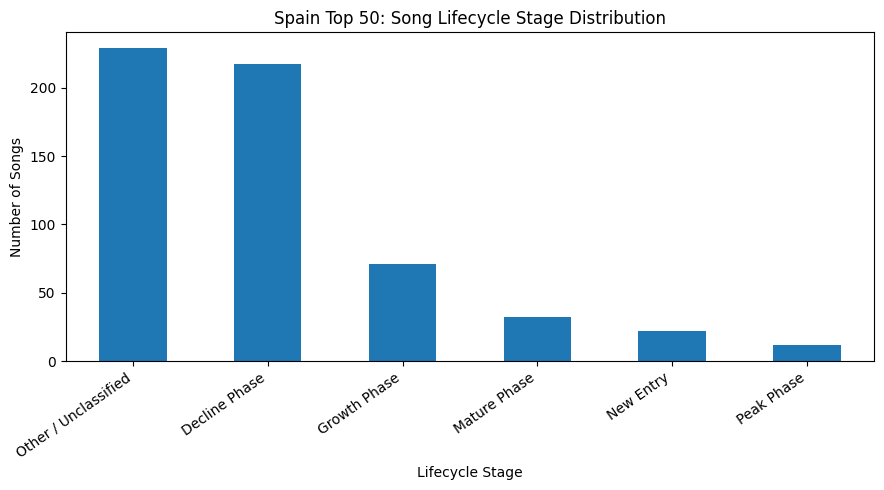

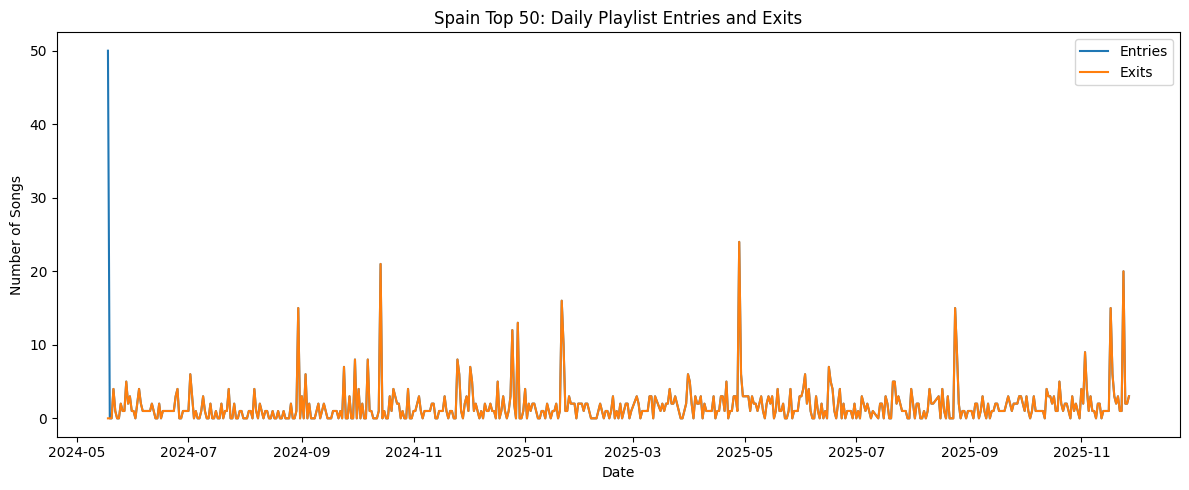

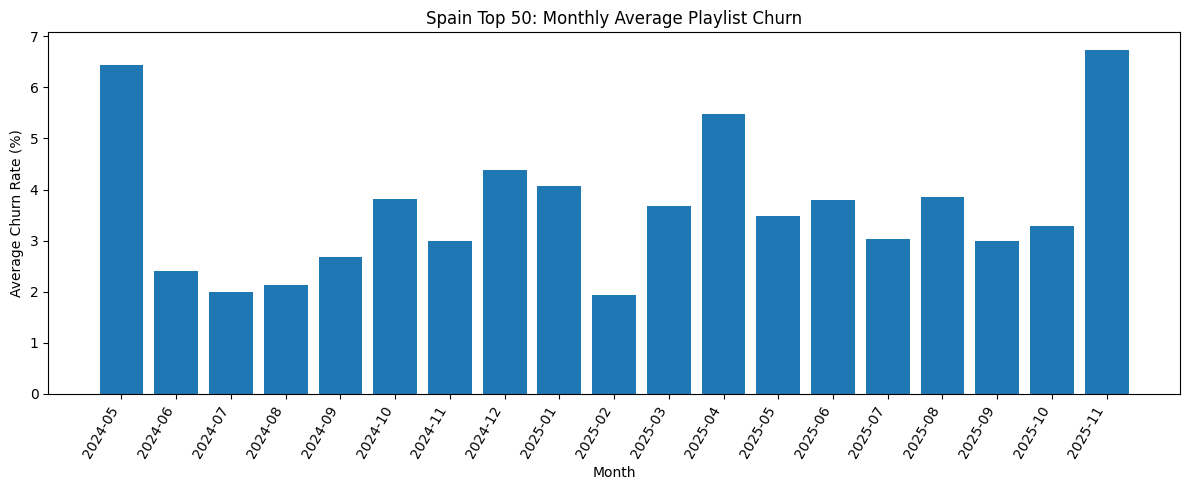

In [ ]:

import matplotlib.pyplot as plt

# Chart 1: Lifecycle stage distribution
stage_counts = recent_trend["lifecycle_stage"].value_counts()

plt.figure(figsize=(9, 5))
stage_counts.plot(kind="bar")
plt.title("Spain Top 50: Song Lifecycle Stage Distribution")
plt.xlabel("Lifecycle Stage")
plt.ylabel("Number of Songs")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


# Chart 2: Daily entries vs exits
plt.figure(figsize=(12, 5))
plt.plot(
    daily_comparisons["date"],
    daily_comparisons["entries"],
    label="Entries"
)
plt.plot(
    daily_comparisons["date"],
    daily_comparisons["exits"],
    label="Exits"
)
plt.title("Spain Top 50: Daily Playlist Entries and Exits")
plt.xlabel("Date")
plt.ylabel("Number of Songs")
plt.legend()
plt.tight_layout()
plt.show()


# Chart 3: Monthly average churn rate
plt.figure(figsize=(12, 5))
plt.bar(
    monthly_rotation["month"],
    monthly_rotation["average_churn_rate_pct"]
)
plt.title("Spain Top 50: Monthly Average Playlist Churn")
plt.xlabel("Month")
plt.ylabel("Average Churn Rate (%)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


# **content-comparison charts**

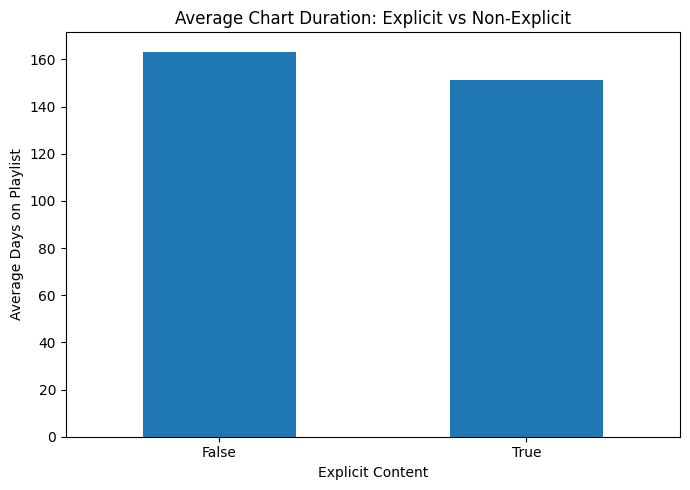

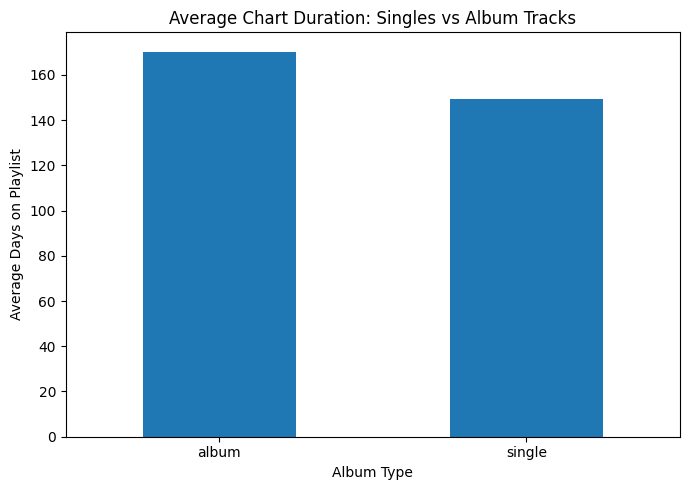

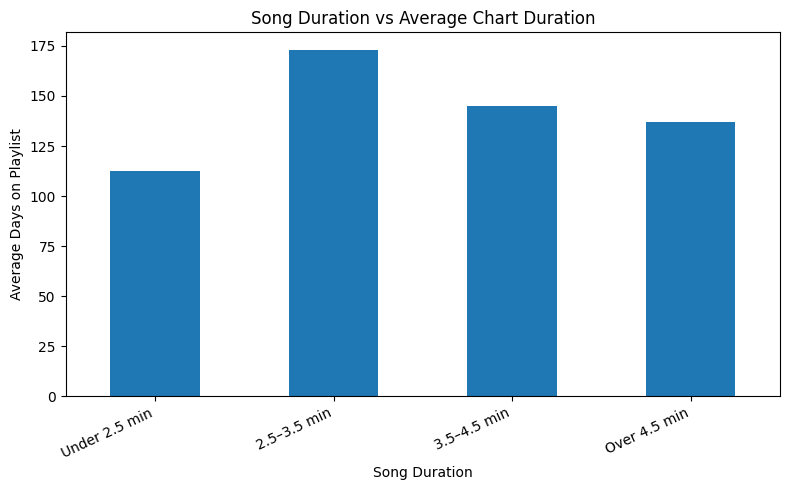

In [ ]:

import matplotlib.pyplot as plt

# 4. Explicit vs non-explicit content
explicit_chart = (
    content_data.groupby("is_explicit")["days_on_chart"]
    .mean()
)

plt.figure(figsize=(7, 5))
explicit_chart.plot(kind="bar")
plt.title("Average Chart Duration: Explicit vs Non-Explicit")
plt.xlabel("Explicit Content")
plt.ylabel("Average Days on Playlist")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 5. Single vs album tracks
album_chart = (
    content_data.groupby("album_type")["days_on_chart"]
    .mean()
)

plt.figure(figsize=(7, 5))
album_chart.plot(kind="bar")
plt.title("Average Chart Duration: Singles vs Album Tracks")
plt.xlabel("Album Type")
plt.ylabel("Average Days on Playlist")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 6. Song duration vs chart duration
duration_chart = (
    content_data.groupby(
        pd.cut(
            content_data["duration_ms"] / 60000,
            bins=[0, 2.5, 3.5, 4.5, float("inf")],
            labels=["Under 2.5 min", "2.5–3.5 min",
                    "3.5–4.5 min", "Over 4.5 min"]
        ),
        observed=False
    )["days_on_chart"]
    .mean()
)

plt.figure(figsize=(8, 5))
duration_chart.plot(kind="bar")
plt.title("Song Duration vs Average Chart Duration")
plt.xlabel("Song Duration")
plt.ylabel("Average Days on Playlist")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

from pathlib import Path
import matplotlib.pyplot as plt

# Folder for project figures
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Recreate and save the six charts
charts = [
    ("lifecycle_stage_distribution.png", stage_counts,
     "Spain Top 50: Song Lifecycle Stage Distribution",
     "Lifecycle Stage", "Number of Songs"),
    ("daily_entries_exits.png", None,
     "Spain Top 50: Daily Playlist Entries and Exits",
     "Date", "Number of Songs"),
    ("monthly_churn.png", monthly_rotation.set_index("month")["average_churn_rate_pct"],
     "Spain Top 50: Monthly Average Playlist Churn",
     "Month", "Average Churn Rate (%)"),
    ("explicit_vs_nonexplicit.png", explicit_chart,
     "Average Chart Duration: Explicit vs Non-Explicit",
     "Explicit Content", "Average Days on Playlist"),
    ("single_vs_album.png", album_chart,
     "Average Chart Duration: Singles vs Album Tracks",
     "Album Type", "Average Days on Playlist"),
    ("duration_vs_longevity.png", duration_chart,
     "Song Duration vs Average Chart Duration",
     "Song Duration", "Average Days on Playlist")
]

for filename, data, title, xlabel, ylabel in charts:
    plt.figure(figsize=(10, 5))

    if filename == "daily_entries_exits.png":
        plt.plot(daily_comparisons["date"], daily_comparisons["entries"], label="Entries")
        plt.plot(daily_comparisons["date"], daily_comparisons["exits"], label="Exits")
        plt.legend()
    else:
        data.plot(kind="bar")

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / filename, dpi=150, bbox_inches="tight")
    plt.close()

print("Saved figures to:", FIGURES_DIR)
print("Number of charts saved:", len(charts))
print("Files:")
for path in sorted(FIGURES_DIR.glob("*.png")):
    print("-", path.name)


Saved figures to: /content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis/reports/figures
Number of charts saved: 6
Files:
- daily_entries_exits.png
- duration_vs_longevity.png
- explicit_vs_nonexplicit.png
- lifecycle_stage_distribution.png
- monthly_churn.png
- single_vs_album.png


# **Prepare the datasets for Power BI.**

In [ ]:

# Create Power BI export folder
POWER_BI_DIR = PROJECT_DIR / "power_bi"
POWER_BI_DIR.mkdir(parents=True, exist_ok=True)

# 1. Song lifecycle data
song_lifecycle.to_csv(
    POWER_BI_DIR / "song_lifecycle.csv",
    index=False
)

# 2. Daily playlist rotation data
daily_comparisons.to_csv(
    POWER_BI_DIR / "daily_rotation.csv",
    index=False
)

# 3. Lifecycle stage data
recent_trend.to_csv(
    POWER_BI_DIR / "lifecycle_stages.csv",
    index=False
)

print("Power BI files saved successfully:")
for file in sorted(POWER_BI_DIR.glob("*.csv")):
    print(f"{file.name} — {file.stat().st_size:,} bytes")


Power BI files saved successfully:
daily_rotation.csv — 17,157 bytes
lifecycle_stages.csv — 107,157 bytes
song_lifecycle.csv — 54,955 bytes


In [ ]:

import shutil
from google.colab import files

# Create a ZIP containing the Power BI CSV files
zip_path = shutil.make_archive(
    "/content/Spain_Top50_PowerBI_Files",
    "zip",
    str(POWER_BI_DIR)
)

# Download the ZIP to your laptop
files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
from google.colab import drive
from pathlib import Path

# Connect Google Drive
drive.mount("/content/drive")

# Set the existing project folder
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis"
)

# Check the files we need
print("Project folder exists:", PROJECT_DIR.exists())
print("\nProcessed data files:")

for file in (PROJECT_DIR / "data" / "processed").glob("*"):
    print(file.name)

print("\nPower BI / dashboard data files:")

for file in (PROJECT_DIR / "power_bi").glob("*"):
    print(file.name)

Mounted at /content/drive
Project folder exists: True

Processed data files:
spain_top50_cleaned.csv
spain_top50_lifecycle_stages.csv

Power BI / dashboard data files:
song_lifecycle.csv
daily_rotation.csv
lifecycle_stages.csv


In [2]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis"
)

for folder in ["data/processed", "power_bi", "reports/figures"]:
    path = PROJECT_DIR / folder
    print(f"\n{folder}:")
    if path.exists():
        for file in path.iterdir():
            print(" -", file.name)
    else:
        print("Folder not found")


data/processed:
 - spain_top50_cleaned.csv
 - spain_top50_lifecycle_stages.csv

power_bi:
 - song_lifecycle.csv
 - daily_rotation.csv
 - lifecycle_stages.csv

reports/figures:
 - lifecycle_stage_distribution.png
 - daily_entries_exits.png
 - monthly_churn.png
 - explicit_vs_nonexplicit.png
 - single_vs_album.png
 - duration_vs_longevity.png


# **Install Streamlit and Plotly**

In [3]:
%pip install -q streamlit plotly

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 86.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 100.4 MB/s eta 0:00:00


# **Create the dashboard file**

In [4]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis"
)

APP_DIR = PROJECT_DIR / "streamlit_app"
APP_DIR.mkdir(parents=True, exist_ok=True)

APP_FILE = APP_DIR / "app.py"

if not APP_FILE.exists():
    APP_FILE.write_text(
        "# Spain Top 50 Songs — Interactive Analytics Dashboard\n",
        encoding="utf-8"
    )

print("App folder:", APP_DIR)
print("App file created:", APP_FILE.exists())

App folder: /content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis/streamlit_app
App file created: True


# **Add the dashboard code**

In [5]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis"
)
APP_FILE = PROJECT_DIR / "streamlit_app" / "app.py"

app_code = r'''
import streamlit as st
import pandas as pd
import plotly.express as px
from pathlib import Path

st.set_page_config(
    page_title="Spain Top 50 | Song Analytics",
    page_icon="🎵",
    layout="wide"
)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis"
)

@st.cache_data
def load_data():
    data_dir = PROJECT_DIR / "data" / "processed"
    export_dir = PROJECT_DIR / "power_bi"

    songs = pd.read_csv(data_dir / "spain_top50_cleaned.csv")
    lifecycle = pd.read_csv(export_dir / "song_lifecycle.csv")
    stages = pd.read_csv(export_dir / "lifecycle_stages.csv")
    rotation = pd.read_csv(export_dir / "daily_rotation.csv")

    songs["date"] = pd.to_datetime(songs["date"], errors="coerce")
    rotation["date"] = pd.to_datetime(rotation["date"], errors="coerce")

    return songs, lifecycle, stages, rotation

songs, lifecycle, stages, rotation = load_data()

st.title("🎵 Spain Top 50 Songs")
st.subheader("Content Maturity, Chart Longevity & Playlist Rotation")
st.caption("Analysis period: May 2024 – November 2025")

st.sidebar.header("Dashboard Filters")

min_date = songs["date"].min().date()
max_date = songs["date"].max().date()

date_range = st.sidebar.date_input(
    "Select date range",
    value=(min_date, max_date),
    min_value=min_date,
    max_value=max_date
)

stage_options = sorted(stages["lifecycle_stage"].dropna().unique())
selected_stages = st.sidebar.multiselect(
    "Lifecycle stage",
    options=stage_options,
    default=stage_options
)

explicit_filter = st.sidebar.selectbox(
    "Explicit content",
    ["All", "Explicit", "Non-explicit"]
)

album_filter = st.sidebar.selectbox(
    "Album type",
    ["All", "Single", "Album"]
)

if len(date_range) == 2:
    start_date, end_date = date_range
else:
    start_date, end_date = min_date, max_date

filtered_songs = songs[
    songs["date"].between(
        pd.Timestamp(start_date),
        pd.Timestamp(end_date) + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)
    )
].copy()

filtered_stages = stages.copy()

if selected_stages:
    filtered_stages = filtered_stages[
        filtered_stages["lifecycle_stage"].isin(selected_stages)
    ]
else:
    filtered_stages = filtered_stages.iloc[0:0]

if explicit_filter != "All":
    desired = explicit_filter == "Explicit"
    filtered_songs = filtered_songs[
        filtered_songs["is_explicit"].astype(str).str.lower().isin(
            ["true", "1"] if desired else ["false", "0"]
        )
    ]

if album_filter != "All":
    filtered_songs = filtered_songs[
        filtered_songs["album_type"].str.lower() == album_filter.lower()
    ]

st.markdown("### Key Performance Indicators")

c1, c2, c3, c4 = st.columns(4)

avg_days = lifecycle["days_on_chart"].mean()
avg_peak = lifecycle["time_to_peak_days"].mean()

valid_rotation = rotation["churn_rate_pct"].dropna()
avg_churn = valid_rotation.mean() if not valid_rotation.empty else 0

persistence = (
    lifecycle["days_on_chart"] /
    (
        (pd.to_datetime(lifecycle["last_seen"]) -
         pd.to_datetime(lifecycle["first_seen"])).dt.days + 1
    )
).mean() * 100

c1.metric("Avg. Days on Playlist", f"{avg_days:.1f}")
c2.metric("Avg. Time to Peak", f"{avg_peak:.1f} days")
c3.metric("Avg. Playlist Churn", f"{avg_churn:.2f}%")
c4.metric("Retention Stability", f"{persistence:.2f}%")

st.markdown("---")
st.caption(
    f"Showing {len(filtered_songs):,} chart observations "
    f"for the selected filters."
)

st.info("Dashboard layout and KPI cards are ready. Interactive charts are coming next.")
'''

APP_FILE.write_text(app_code, encoding="utf-8")

print("Dashboard code saved to:", APP_FILE)
print("File size:", APP_FILE.stat().st_size, "bytes")

Dashboard code saved to: /content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis/streamlit_app/app.py
File size: 3546 bytes


# **Add interactive graphs**

In [6]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis"
)
APP_FILE = PROJECT_DIR / "streamlit_app" / "app.py"

charts_code = r'''

st.markdown("---")
st.header("📊 Playlist Lifecycle & Rotation")

# 1. Lifecycle stage distribution
left, right = st.columns(2)

with left:
    st.subheader("Lifecycle Stage Distribution")
    if not filtered_stages.empty:
        stage_counts = (
            filtered_stages.groupby("lifecycle_stage")
            .size()
            .reset_index(name="Song Count")
        )
        fig = px.bar(
            stage_counts,
            x="lifecycle_stage",
            y="Song Count",
            color="lifecycle_stage",
            title="Songs by Lifecycle Stage",
            labels={
                "lifecycle_stage": "Lifecycle Stage",
                "Song Count": "Number of Songs"
            }
        )
        fig.update_layout(showlegend=False)
        st.plotly_chart(fig, use_container_width=True)
    else:
        st.warning("Select at least one lifecycle stage.")

# 2. Daily entries and exits
with right:
    st.subheader("Daily Playlist Rotation")
    rotation_view = rotation[
        rotation["date"].between(
            pd.Timestamp(start_date),
            pd.Timestamp(end_date)
        )
    ].copy()

    rotation_view = rotation_view.dropna(subset=["entries", "exits"])
    rotation_view = rotation_view[
        (rotation_view["entries"] != 50) |
        (rotation_view["exits"] != 0)
    ]

    if not rotation_view.empty:
        daily_long = rotation_view.melt(
            id_vars="date",
            value_vars=["entries", "exits"],
            var_name="Movement",
            value_name="Songs"
        )
        fig = px.line(
            daily_long,
            x="date",
            y="Songs",
            color="Movement",
            markers=False,
            title="Daily Entries vs. Exits"
        )
        st.plotly_chart(fig, use_container_width=True)
    else:
        st.info("No daily rotation data is available for this date range.")

# 3. Monthly churn
st.subheader("Monthly Playlist Churn")

monthly_view = rotation[
    rotation["date"].between(
        pd.Timestamp(start_date),
        pd.Timestamp(end_date)
    )
].dropna(subset=["churn_rate_pct"]).copy()

if not monthly_view.empty:
    monthly_view["month"] = (
        monthly_view["date"].dt.to_period("M").astype(str)
    )
    monthly_summary = (
        monthly_view.groupby("month", as_index=False)
        ["churn_rate_pct"].mean()
    )
    fig = px.bar(
        monthly_summary,
        x="month",
        y="churn_rate_pct",
        title="Average Monthly Churn Rate",
        labels={
            "month": "Month",
            "churn_rate_pct": "Average Churn Rate (%)"
        }
    )
    st.plotly_chart(fig, use_container_width=True)

# 4. Explicit vs. non-explicit content
st.markdown("---")
st.header("🎧 Content Analysis")

left, right = st.columns(2)

with left:
    st.subheader("Explicit vs. Non-explicit")

    if not filtered_songs.empty:
        explicit_summary = (
            filtered_songs.assign(
                content_type=filtered_songs["is_explicit"].map(
                    {True: "Explicit", False: "Non-explicit",
                     "True": "Explicit", "False": "Non-explicit"}
                ).fillna("Unknown")
            )
            .groupby("content_type", as_index=False)
            .agg(
                Chart_Observations=("song", "size"),
                Avg_Popularity=("popularity", "mean")
            )
        )

        fig = px.bar(
            explicit_summary,
            x="content_type",
            y="Chart_Observations",
            color="content_type",
            title="Chart Observations by Content Type"
        )
        fig.update_layout(showlegend=False)
        st.plotly_chart(fig, use_container_width=True)

with right:
    st.subheader("Singles vs. Albums")

    if not filtered_songs.empty:
        album_summary = (
            filtered_songs.groupby("album_type", as_index=False)
            .agg(
                Chart_Observations=("song", "size"),
                Avg_Popularity=("popularity", "mean")
            )
        )
        fig = px.bar(
            album_summary,
            x="album_type",
            y="Avg_Popularity",
            color="album_type",
            title="Average Popularity by Release Type",
            labels={"Avg_Popularity": "Average Popularity Score"}
        )
        fig.update_layout(showlegend=False)
        st.plotly_chart(fig, use_container_width=True)

# 5. Song duration vs. playlist longevity
st.markdown("---")
st.header("⏱️ Song Duration vs. Playlist Longevity")

metadata = (
    songs[["song", "artist", "duration_ms", "album_type"]]
    .drop_duplicates(subset=["song", "artist"])
)

longevity = metadata.merge(
    lifecycle[["song", "artist", "days_on_chart"]],
    on=["song", "artist"],
    how="inner"
)

if not longevity.empty:
    longevity["duration_minutes"] = (
        longevity["duration_ms"] / 60000
    )

    fig = px.scatter(
        longevity,
        x="duration_minutes",
        y="days_on_chart",
        color="album_type",
        hover_name="song",
        hover_data=["artist"],
        title="Does Song Duration Relate to Playlist Longevity?",
        labels={
            "duration_minutes": "Song Duration (minutes)",
            "days_on_chart": "Days on Playlist",
            "album_type": "Release Type"
        }
    )
    st.plotly_chart(fig, use_container_width=True)

st.caption(
    "Note: Spotify popularity is a score, not a stream count. "
    "Playlist observations do not represent total listening volume."
)
'''

with APP_FILE.open("a", encoding="utf-8") as file:
    file.write(charts_code)

print("Interactive chart code added successfully.")
print("File size:", APP_FILE.stat().st_size, "bytes")

Interactive chart code added successfully.
File size: 9059 bytes


# **Check the app before launching**

In [7]:
import py_compile

APP_FILE = (
    "/content/drive/MyDrive/"
    "Spain_Top50_Lifecycle_Analysis/"
    "streamlit_app/app.py"
)

py_compile.compile(APP_FILE, doraise=True)

print("Success! No Python syntax errors found.")

Success! No Python syntax errors found.


# **Launch Streamlit in Google Colab**

In [8]:
%pip install -q pyngrok

# **Start Streamlit**

In [9]:
import subprocess
import time
from pathlib import Path
from IPython.display import display, HTML
from google.colab.output import eval_js

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis"
)
APP_FILE = PROJECT_DIR / "streamlit_app" / "app.py"
LOG_FILE = PROJECT_DIR / "streamlit_app" / "streamlit.log"

# Stop an earlier Streamlit process from this notebook, if present
if "streamlit_process" in globals():
    if streamlit_process.poll() is None:
        streamlit_process.terminate()
        streamlit_process.wait()

# Start Streamlit in the background
log_handle = open(LOG_FILE, "w")

streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", str(APP_FILE),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_handle,
    stderr=subprocess.STDOUT
)

# Give the app time to start
time.sleep(5)

if streamlit_process.poll() is not None:
    print("Streamlit stopped. Check the log:")
    print(LOG_FILE.read_text(encoding="utf-8")[-4000:])
else:
    url = eval_js("google.colab.kernel.proxyPort(8501)")
    print("Your dashboard link:")
    display(HTML(f'<a href="{url}" target="_blank">{url}</a>'))

Your dashboard link:


In [10]:
from pathlib import Path

LOG_FILE = Path(
    "/content/drive/MyDrive/"
    "Spain_Top50_Lifecycle_Analysis/"
    "streamlit_app/streamlit.log"
)

if LOG_FILE.exists():
    print(LOG_FILE.read_text(encoding="utf-8")[-6000:])
else:
    print("Log file not found.")

rigin=https://8501-m-s-kkb-euw4b2-3m7hnbmpewul2-b.europe-west4-2.prod.colab.dev, host=m-s-kkb-euw4b2-3m7hnbmpewul2.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-10-22 15:46:34.894 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-kkb-euw4b2-3m7hnbmpewul2-b.europe-west4-2.prod.colab.dev, host=m-s-kkb-euw4b2-3m7hnbmpewul2.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-10-22 15:46:39.830 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-kkb-euw4b2-3m7hnbmpewul2-b.europe-west4-2.prod.colab.dev, host=m-s-kkb-euw4b2-3m7hnbmpewul2.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-10-22 15:46:45.788 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-kkb-euw4b2-3m7hnbmpewul2-b.europe-west4-2.prod.colab.dev, host=m-s-kkb-euw4b2-3m7hnbmpewul2.europe-west4-b.c.codatalab-user-runtimes.internal:8007
2026-10-22 15:46:51.941 Rejecting W

# **Restart Streamlit with the correct settings**

In [11]:
import subprocess
import time
from pathlib import Path
from IPython.display import display, HTML
from google.colab.output import eval_js

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis"
)
APP_FILE = PROJECT_DIR / "streamlit_app" / "app.py"
LOG_FILE = PROJECT_DIR / "streamlit_app" / "streamlit.log"

# Stop the previous process
if "streamlit_process" in globals():
    if streamlit_process.poll() is None:
        streamlit_process.terminate()
        streamlit_process.wait()

# Restart Streamlit with proxy-friendly settings
log_handle = open(LOG_FILE, "w")

streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", str(APP_FILE),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false",
        "--browser.gatherUsageStats", "false"
    ],
    stdout=log_handle,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Process running:", streamlit_process.poll() is None)

url = eval_js("google.colab.kernel.proxyPort(8501)")
print("Open this dashboard link:")
display(HTML(f'<a href="{url}" target="_blank">{url}</a>'))

Process running: True
Open this dashboard link:


In [12]:
from pathlib import Path
import shutil

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis"
)

DEPLOY_DIR = PROJECT_DIR / "streamlit_deploy"

# Create deployment folders
(DEPLOY_DIR / "data" / "processed").mkdir(
    parents=True, exist_ok=True
)
(DEPLOY_DIR / "power_bi").mkdir(
    parents=True, exist_ok=True
)

# Copy the app
shutil.copy2(
    PROJECT_DIR / "streamlit_app" / "app.py",
    DEPLOY_DIR / "app.py"
)

# Copy required data files
files_to_copy = [
    (
        PROJECT_DIR / "data" / "processed"
        / "spain_top50_cleaned.csv",
        DEPLOY_DIR / "data" / "processed"
        / "spain_top50_cleaned.csv"
    ),
    (
        PROJECT_DIR / "power_bi" / "song_lifecycle.csv",
        DEPLOY_DIR / "power_bi" / "song_lifecycle.csv"
    ),
    (
        PROJECT_DIR / "power_bi" / "daily_rotation.csv",
        DEPLOY_DIR / "power_bi" / "daily_rotation.csv"
    ),
    (
        PROJECT_DIR / "power_bi" / "lifecycle_stages.csv",
        DEPLOY_DIR / "power_bi" / "lifecycle_stages.csv"
    )
]

for source, destination in files_to_copy:
    shutil.copy2(source, destination)

# Make paths portable for online deployment
app_path = DEPLOY_DIR / "app.py"
app_code = app_path.read_text(encoding="utf-8")

old_path = '''PROJECT_DIR = Path(
    "/content/drive/MyDrive/Spain_Top50_Lifecycle_Analysis"
)'''

new_path = '''PROJECT_DIR = Path(__file__).resolve().parent'''

if old_path in app_code:
    app_code = app_code.replace(old_path, new_path, 1)
    app_path.write_text(app_code, encoding="utf-8")
    print("App paths updated for deployment.")
else:
    print("App path pattern not found; inspect app.py before deploying.")

# Create dependency file
(DEPLOY_DIR / "requirements.txt").write_text(
    "streamlit\npandas\nplotly\n",
    encoding="utf-8"
)

print("\nDeployment files:")
for file in sorted(DEPLOY_DIR.rglob("*")):
    if file.is_file():
        print(file.relative_to(DEPLOY_DIR))

App paths updated for deployment.

Deployment files:
app.py
data/processed/spain_top50_cleaned.csv
power_bi/daily_rotation.csv
power_bi/lifecycle_stages.csv
power_bi/song_lifecycle.csv
requirements.txt
